<a href="https://colab.research.google.com/github/Swathi04705/APS/blob/main/APS_dataset.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
#Import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix

In [ ]:
#load the datset
data = load_breast_cancer()

X = pd.DataFrame(
    data=data.data,
    columns=data.feature_names
)

y = pd.Series(
    (data.target == 0).astype(int),
    name = "malignant"
)

print(y.value_counts())

print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)
print("Class Name:", data.target_names)

malignant
0    357
1    212
Name: count, dtype: int64
Feature matrix shape: (569, 30)
Target shape: (569,)
Class Name: ['malignant' 'benign']


In [ ]:
class_counts = y.value_counts().sort_index()

class_distribution = pd.DataFrame({
    "Class": ["Benign", "Malignant"],
    "Count": [class_counts.loc[0], class_counts.loc[1]],
    "Probability": [
        class_counts.loc[0] / len(y),
        class_counts.loc[1] / len(y)
    ]
})

print(class_distribution)

       Class  Count  Probability
0     Benign    357     0.627417
1  Malignant    212     0.372583


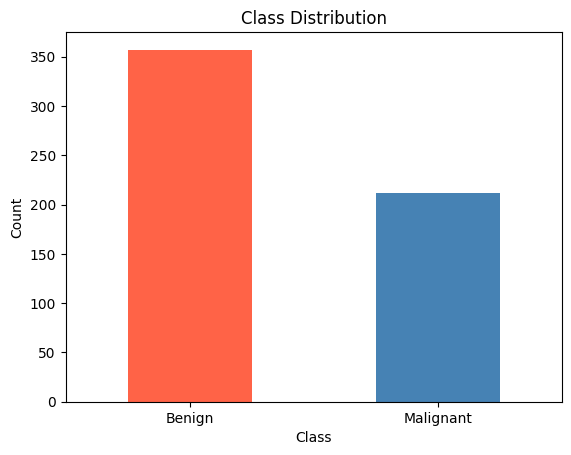

In [ ]:
class_distribution.plot(
    x = "Class",
    y = "Count",
    kind = "bar",
    legend = False,
    color = ["tomato", "steelblue"]
)

plt.ylabel("Count")
plt.title("Class Distribution")
plt.xticks(rotation = 0)
plt.show()


are malignant and benign outcomes equally likely in this dataset?

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size = 0.20,
    random_state = 42,
    stratify = y
)

print("Training size:", len(y_train))
print("Testing size:", len(y_test))

print("\ntraining proportions:")
print(y_train.value_counts(normalize=True))

print("\ntesting proportions:")
print(y_test.value_counts(normalize=True).sort_index())

print("\ntraining proportions:")
print(y_train.value_counts(normalize=True).sort_index())


Training size: 455
Testing size: 114

training proportions:
malignant
0    0.626374
1    0.373626
Name: proportion, dtype: float64

testing proportions:
malignant
0    0.631579
1    0.368421
Name: proportion, dtype: float64

training proportions:
malignant
0    0.626374
1    0.373626
Name: proportion, dtype: float64


In [ ]:
#Train a logistic regression model
model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000)
)

model.fit(X_train, y_train)


Pipeline(steps=[('standardscaler', StandardScaler()),
                ('logisticregression', LogisticRegression(max_iter=1000))])

In [ ]:
#obtain predicted probability
probabilities = model.predict_proba(X_test)
print(probabilities[:5])

[[9.99635432e-01 3.64568116e-04]
 [1.07465986e-08 9.99999989e-01]
 [9.57432053e-01 4.25679471e-02]
 [4.23812678e-01 5.76187322e-01]
 [4.90844511e-01 5.09155489e-01]]


In [ ]:
print(probabilities[:5].sum(axis=1))

[1. 1. 1. 1. 1.]


In [ ]:
results = pd.DataFrame({
    "Actual class": y_test.values,
    "P_malignant": probabilities[:, 0],
    "P_Benign": probabilities[:, 1]
})

print(results.head(10))


   Actual class   P_malignant  P_Benign
0             0  9.996354e-01  0.000365
1             1  1.074660e-08  1.000000
2             0  9.574321e-01  0.042568
3             1  4.238127e-01  0.576187
4             0  4.908445e-01  0.509155
5             0  9.993840e-01  0.000616
6             1  2.384659e-01  0.761534
7             0  9.989878e-01  0.001012
8             0  9.994313e-01  0.000569
9             0  9.892324e-01  0.010768


In [ ]:
threshold = 0.50

results["predicted_malignant"]=(
    results["P_malignant"] >= threshold
).astype(int)

results["Actual_label"]=results["Actual class"].map({
    1:"Benign",
    0:"Malignant"
})

results["Predicted_label"]=results["predicted_malignant"].map({
    1:"Malignant",
    0:"Benign"
})

print(
    results[
        ["Actual_label", "P_malignant", "Predicted_label"]
        ]
    .head(10)
)




  Actual_label   P_malignant Predicted_label
0    Malignant  9.996354e-01       Malignant
1       Benign  1.074660e-08          Benign
2    Malignant  9.574321e-01       Malignant
3       Benign  4.238127e-01          Benign
4    Malignant  4.908445e-01          Benign
5    Malignant  9.993840e-01       Malignant
6       Benign  2.384659e-01          Benign
7    Malignant  9.989878e-01       Malignant
8    Malignant  9.994313e-01       Malignant
9    Malignant  9.892324e-01       Malignant


In [ ]:
for threshold in [0.30,0.50,0.70]:
  predictions=results["predicted_malignant"]=(
      results["P_malignant"] >= threshold
  ).astype(int)

  print(f"\nThreshold = {threshold}")
  print(f"predicted malignant class={predictions.sum()}")


Threshold = 0.3
predicted malignant class=76

Threshold = 0.5
predicted malignant class=74

Threshold = 0.7
predicted malignant class=72


In [ ]:
actual_malignant = (y_test.values == 0).astype(int)

for threshold in [0.30,0.50,0.70]:
  predicted_malignant =(
      probabilities[:, 0] >= threshold
  ).astype(int)

  cm = confusion_matrix(
      actual_malignant,
      predicted_malignant
  )

  print(f"\nThreshold = {threshold}")
  print(cm)




Threshold = 0.3
[[38  4]
 [ 0 72]]

Threshold = 0.5
[[39  3]
 [ 1 71]]

Threshold = 0.7
[[41  1]
 [ 1 71]]


In [ ]:
#verify using sklearn
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)
print(
    "sklearn accuracy:",
    accuracy_score(y_test, predictions)
)

print(
    "sklearn precision:",
    precision_score(y_test, predictions)
)

print(
    "sklearn recall:",
    recall_score(y_test, predictions)
)

print("sklearn f1:",
      f1_score(y_test, predictions)
)

sklearn accuracy: 0.017543859649122806
sklearn precision: 0.013888888888888888
sklearn recall: 0.023809523809523808
sklearn f1: 0.017543859649122806


In [ ]:
metric_results = []

for threshold in [0.10, 0.30, 0.50, 0.70, 0.90]:
    y_pred_threshold = (
      probabilities[:,1] >= threshold
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_test,
        y_pred_threshold,
        labels = [0,1]
    ).ravel()

    accuracy = (tp + tn) / (tp + fp + tn + fn)
    precision = tp / (tp + fp) if (tp + fp) > 0 else 0 # among the tumours predicted as malignant, how many were actually malignant
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0 #sensitivity
    specificity = tn / (tn + fp) if (tn + fp) > 0 else 0

    f1 = (
        2 * (precision * recall) / (precision + recall)
        if (precision + recall) > 0 else 0
    )

    metric_results.append({
        "Threshold": threshold,
        "TN": tn,
        "FP": fp,
        "FN": fn,
        "TP": tp,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall_sensitivity": recall,
        "Specificity": specificity,
        "F1": f1
    })

    metric_results_df = pd.DataFrame(metric_results)

display(metric_results_df.round(3))

,Threshold,TN,FP,FN,TP,Accuracy,Precision,Recall_sensitivity,Specificity,F1
0,0.1,67,5,1,41,0.947,0.891,0.976,0.931,0.932
1,0.3,71,1,1,41,0.982,0.976,0.976,0.986,0.976
2,0.5,71,1,3,39,0.965,0.975,0.929,0.986,0.951
3,0.7,72,0,4,38,0.965,1.000,0.905,1.000,0.950
4,0.9,72,0,9,33,0.921,1.000,0.786,1.000,0.880


**at which threshold are the fewest malignant missed?**

**what happens to false positives when the threshold decreases?**

**which threshold provides the highest specificity**->0.9

**which threshold gives best F1 score**->

**